In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.datasets import load_wine
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

In [ ]:
#Load and standardize the dataset
data = load_wine(as_frame=True)

X = data.data
y = data.target

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Samples:", X.shape[0])
print("Original features:", X.shape[1])
print("Classes:", list(data.target_names))

Samples: 178
Original features: 13
Classes: [np.str_('class_0'), np.str_('class_1'), np.str_('class_2')]


In [ ]:
#Explained variance
pca_full = PCA()
X_pca_full = pca_full.fit_transform(X_scaled)

variance_table = pd.DataFrame({
    "Component": np.arange(
        1, len(pca_full.explained_variance_ratio_) + 1
    ),
    "Explained variance": pca_full.explained_variance_ratio_,
    "Cumulative variance": np.cumsum(
        pca_full.explained_variance_ratio_
    )
}).set_index("Component")

print(variance_table.head(10).round(4))

           Explained variance  Cumulative variance
Component                                         
1                      0.3620               0.3620
2                      0.1921               0.5541
3                      0.1112               0.6653
4                      0.0707               0.7360
5                      0.0656               0.8016
6                      0.0494               0.8510
7                      0.0424               0.8934
8                      0.0268               0.9202
9                      0.0222               0.9424
10                     0.0193               0.9617


In [ ]:
#Select components preserving 90% variance
components_for_90_percent = int(
    np.argmax(
        variance_table["Cumulative variance"].to_numpy() >= 0.90
    ) + 1
)

print(
    "Components needed for at least 90% variance:",
    components_for_90_percent
)

print(
    "Variance explained by the first two components:",
    round(variance_table["Cumulative variance"].iloc[1], 4)
)

Components needed for at least 90% variance: 8
Variance explained by the first two components: 0.5541


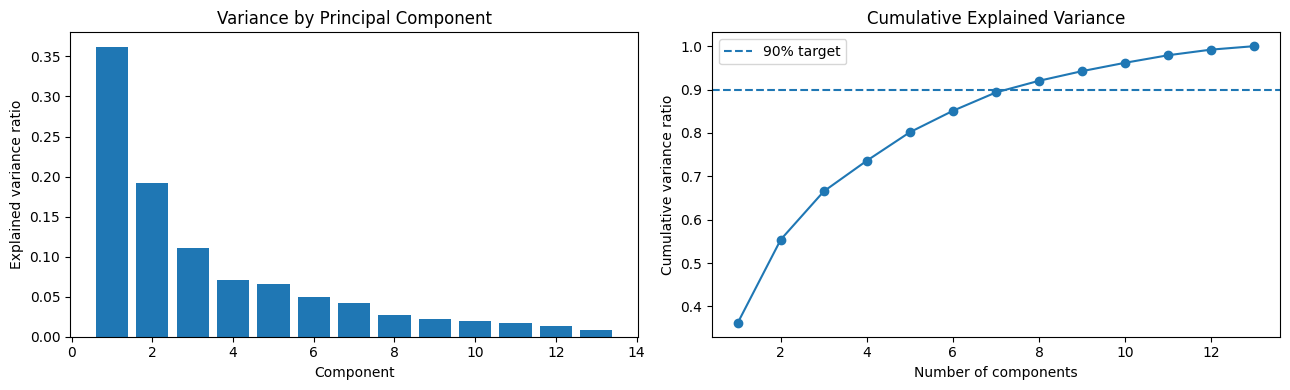

In [ ]:
#Visualize explained variance
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].bar(
    variance_table.index,
    variance_table["Explained variance"]
)

axes[0].set_title("Variance by Principal Component")
axes[0].set_xlabel("Component")
axes[0].set_ylabel("Explained variance ratio")

axes[1].plot(
    variance_table.index,
    variance_table["Cumulative variance"],
    marker="o"
)

axes[1].axhline(
    0.90,
    linestyle="--",
    label="90% target"
)

axes[1].set_title("Cumulative Explained Variance")
axes[1].set_xlabel("Number of components")
axes[1].set_ylabel("Cumulative variance ratio")
axes[1].legend()

plt.tight_layout()
plt.show()

In [ ]:
#Component loadings and dimensionality reduction
pca_2d = PCA(n_components=2)
X_pca_2d = pca_2d.fit_transform(X_scaled)

loadings = pd.DataFrame(
    pca_2d.components_.T,
    index=X.columns,
    columns=["PC1 loading", "PC2 loading"]
)

print("Features with the largest absolute loadings:")

for component in loadings.columns:
    print("\n", component)
    print(
        loadings[component]
        .abs()
        .sort_values(ascending=False)
        .head(5)
        .to_string()
    )

X_reconstructed = pca_2d.inverse_transform(X_pca_2d)

reconstruction_mse = np.mean(
    (X_scaled - X_reconstructed) ** 2
)

print(
    "\nTwo-component reconstruction MSE:",
    round(reconstruction_mse, 4)
)

Features with the largest absolute loadings:

 PC1 loading
flavanoids                      0.422934
total_phenols                   0.394661
od280/od315_of_diluted_wines    0.376167
proanthocyanins                 0.313429
nonflavanoid_phenols            0.298533

 PC2 loading
color_intensity    0.529996
alcohol            0.483652
proline            0.364903
ash                0.316069
magnesium          0.299634

Two-component reconstruction MSE: 0.4459


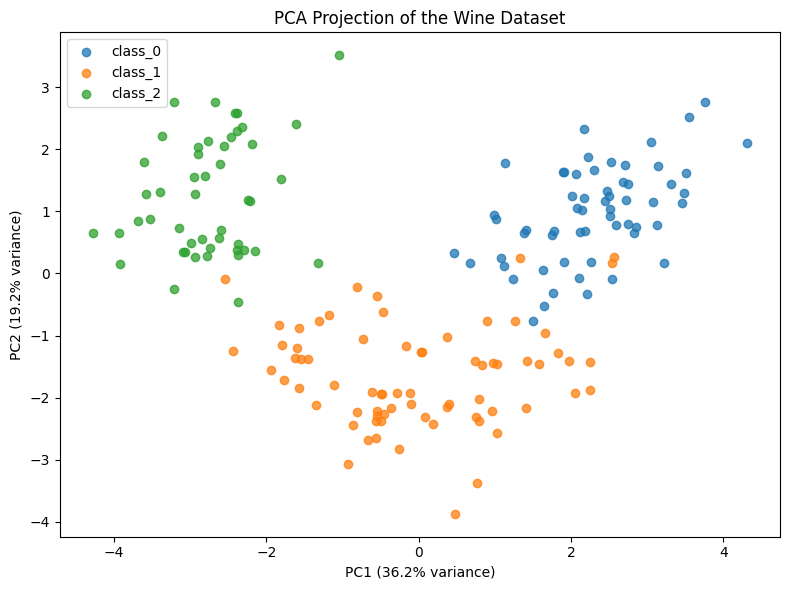

In [ ]:
#Visualize the two-dimensional PCA projection
plt.figure(figsize=(8, 6))

for class_value, class_name in enumerate(data.target_names):
    mask = y == class_value

    plt.scatter(
        X_pca_2d[mask, 0],
        X_pca_2d[mask, 1],
        label=class_name,
        alpha=0.75
    )

plt.xlabel(
    f"PC1 ({pca_2d.explained_variance_ratio_[0]:.1%} variance)"
)

plt.ylabel(
    f"PC2 ({pca_2d.explained_variance_ratio_[1]:.1%} variance)"
)

plt.title("PCA Projection of the Wine Dataset")
plt.legend()
plt.tight_layout()
plt.show()